In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

from utils import projected_graph_custom, bipartite_graph, parse_list, modified_fast_chung_lu_bipartite, get_members_combination, avg_previous_team_rating, avg_previous_individual_exp, avg_previous_tm_exp, avg_previous_tm_shared_colabs, avg_previous_tm_betweenness, avg_previous_tm_closeness, avg_previous_tm_clustering_coeff


# Original Network Setup
Starting with a bipartite graph with 2 sets: Production Participants and Episodes. A link between a participant and an episode is generated if the person worked in the production of said episode.

In [ ]:
df = pd.read_csv("datasets/one_piece_merged.csv")
B = bipartite_graph(df)

# Getting Staff Nodes
staff_nodes = {n for n, d in B.nodes(data=True) if d["bipartite"] == "staff"}

Number of nodes: 1389, Number of edges: 5213


# Bipartite Projection with custom attributes

# Graph evolution through time (episodes), computate and store metrics

In [5]:
# Columns with considered participants
staff_columns = ["guion", "arte", "animacion", "direccion"]
value_columns = ["n de paginas", "rating", "votos"]


B = nx.Graph()
# Starting on empty temporary graphs, as Viana Metrics will eventually require the previous graph for its prodecure
G_temp = None
betweenness_temp = None
staff_nodes_temp = {}
# Add empty lists to store topological metrics
avg_closeness = []
avg_betweenness = []
avg_path_len = []
avg_degree_normalized = []
avg_degree = []
# Empty lists to store Viana's Metrics
avg_previous_tm_exp_list = []
avg_previous_tm_shared_colabs_list = []
avg_previous_tm_clustering_coeff_list = []
avg_previous_tm_closeness_list = []
avg_previous_tm_betweenness_list = []
avg_previous_individual_exp_list = []
avg_previous_team_rating_list = []

for _, row in df.iterrows():
    episodio = f"ep_{int(row['episodio'])}"
    B_prev = B
    B.add_node(episodio, bipartite="episode")

    value_dict = {}
    for val in value_columns:
        value_dict[val] = row[val]
    
    nx.set_node_attributes(B, {episodio: value_dict})
    colabs = []
    for col in staff_columns:
        personas = parse_list(row[col])
        
        for persona in personas:
            persona_clean = persona.split("(")[0].strip()

            # Add a participant iff it has not yet appeared
            if persona_clean == '':
                continue
            colabs.append(persona_clean)
            B.add_node(persona_clean, bipartite="staff")

            # Adding edge to the resultant graph
            B.add_edge(persona_clean, episodio)
    
    staff_nodes_temp = {n for n, d in B.nodes(data=True) if d["bipartite"] == "staff"}
    G_prev = G_temp
    G_temp = projected_graph_custom(B, staff_nodes_temp)

    # Adding metrics
    # Average Closeness
    avg_closeness.append(np.mean(list(nx.closeness_centrality(G_temp).values())))
    # Characteristic Path Length
    if nx.connected.is_connected(G_temp):
        avg_path_len.append(nx.average_shortest_path_length(G_temp))
    else:
        avg_path_len.append(1)
    # Average normalized degree and mean degree
    avg_degree_normalized.append(np.mean(list(nx.degree_centrality(G_temp).values())))
    avg_degree.append(np.mean(list(dict(G_temp.degree()).values())))
    # Average Betweenness
    betweenness_prev = betweenness_temp
    betweenness_temp = nx.betweenness_centrality(G_temp)
    avg_betweenness.append(np.mean(list(betweenness_temp.values())))

    # Get all participant possible pairs in the specific current team
    pares_colab = get_members_combination(colabs)
    largo_pares = len(pares_colab)

    # Amount of collaborations in the current step
    largo_colabs = len(colabs)

    # Add a null initial value if the previous graph does not exist (meaning it is the execution for the first episode)
    if not G_prev:
        avg_previous_tm_exp_list.append(0)
        avg_previous_tm_shared_colabs_list.append(0)
        avg_previous_tm_clustering_coeff_list.append(0)
        avg_previous_tm_closeness_list.append(0)
        avg_previous_tm_betweenness_list.append(0)
        avg_previous_individual_exp_list.append(0)
        avg_previous_team_rating_list.append(0)
    else: # Else calculate metrics
        avg_previous_tm_exp_list.append(avg_previous_tm_exp(G_prev, pares_colab, largo_pares))
        avg_previous_tm_shared_colabs_list.append(avg_previous_tm_shared_colabs(G_prev, pares_colab, largo_pares))
        avg_previous_tm_clustering_coeff_list.append(avg_previous_tm_clustering_coeff(G_prev, colabs, largo_colabs))
        avg_previous_tm_closeness_list.append(avg_previous_tm_closeness(G_prev, colabs, largo_colabs))
        avg_previous_tm_betweenness_list.append(avg_previous_tm_betweenness(G_prev, colabs, betweenness_prev, largo_colabs))
        avg_previous_individual_exp_list.append(avg_previous_individual_exp(B_prev, colabs, largo_colabs))
        avg_previous_team_rating_list.append(avg_previous_team_rating(B_prev, colabs, largo_colabs))

# Our proposed model
In this section the proposed model based on the Bipartite Chung-Lu model is executed through time.

In [ ]:
# Staff columns
staff_columns = ["guion", "arte", "animacion", "direccion"]
# Value Columns
value_columns = ["n de paginas", "rating", "votos"]
# Define seed
seed = "Eiichirō Oda"
# Random state
rng = random.Random(seed)

B_0 = nx.Graph()
# Starting on empty temporary graphs, as Viana Metrics will eventually require the previous graph for its prodecure
G_temp_0 = None
betweenness_temp_0 = None
staff_nodes_temp_0 = {}
# Add empty lists to store topological metrics
avg_closeness_syn_rl = []
avg_betweenness_syn_rl = []
avg_path_len_syn_rl = []
avg_degree_normalized_syn_rl = []
avg_degree_syn_rl = []
# Empty lists to store Viana's Metrics
avg_previous_tm_exp_list_syn_rl = []
avg_previous_tm_shared_colabs_list_syn_rl = []
avg_previous_tm_clustering_coeff_list_syn_rl = []
avg_previous_tm_closeness_list_syn_rl = []
avg_previous_tm_betweenness_list_syn_rl = []
avg_previous_individual_exp_list_syn_rl = []
avg_previous_team_rating_list_syn_rl = []

global_colabs = []
for _, row in df.iterrows():
    episodio = f"ep_{int(row['episodio'])}"
    B_prev_0 = B_0
    B_0.add_node(episodio, bipartite="episode")

    value_dict = {}
    for val in value_columns:
        value_dict[val] = row[val]
    
    nx.set_node_attributes(B_0, {episodio: value_dict})
    colabs = 0
    for col in staff_columns:
        personas = parse_list(row[col])
        
        for persona in personas:
            persona_clean = persona.split("(")[0].strip()

            # Adding participant node
            if persona_clean == '':
                continue
            global_colabs.append(persona_clean)
            colabs += 1

    # Model execution
    B_0, colabs_0 = modified_fast_chung_lu_bipartite(B_0, global_colabs, episodio, colabs, rng)

    staff_nodes_temp_0 = {n for n, d in B_0.nodes(data=True) if d["bipartite"] == "staff"}
    G_prev_0 = G_temp_0
    G_temp_0 = projected_graph_custom(B_0, staff_nodes_temp_0)

    # Average Closeness
    avg_closeness_0 = np.mean(list(nx.closeness_centrality(G_temp_0).values()))
    avg_closeness_syn_rl.append(avg_closeness_0)
    # Characteristic Path length
    if nx.connected.is_connected(G_temp_0):
        avg_path_len_syn_rl.append(nx.average_shortest_path_length(G_temp_0))
    else:
        avg_path_len_syn_rl.append(1)
    
    # Average (Normalized) Degree
    avg_degree_normalized_0 = np.mean(list(nx.degree_centrality(G_temp_0).values()))
    avg_degree_normalized_syn_rl.append(avg_degree_normalized_0)

    avg_degree_0 = np.mean(list(dict(G_temp_0.degree()).values()))
    avg_degree_syn_rl.append(avg_degree_0)

    # Average Betweenness
    betweenness_prev_0 = betweenness_temp_0
    betweenness_temp_0 = nx.betweenness_centrality(G_temp_0)
    avg_betweenness_syn_rl.append(np.mean(list(betweenness_temp_0.values())))

     # Get all participant possible pairs in the current team
    pares_colab_0 = get_members_combination(colabs_0)
    largo_pares_0 = len(pares_colab_0)

    # Amount of collaborations in the current step
    largo_colabs = colabs

    # Add a null initial value if the previous graph does not exist (meaning it is the execution for the first episode)
    if not G_prev_0:
        avg_previous_tm_exp_list_syn_rl.append(0)
        avg_previous_tm_shared_colabs_list_syn_rl.append(0)
        avg_previous_tm_clustering_coeff_list_syn_rl.append(0)
        avg_previous_tm_closeness_list_syn_rl.append(0)
        avg_previous_tm_betweenness_list_syn_rl.append(0)
        avg_previous_individual_exp_list_syn_rl.append(0)
        avg_previous_team_rating_list_syn_rl.append(0)
    else: # Else calculate metrics
        avg_previous_tm_exp_list_syn_rl.append(avg_previous_tm_exp(G_prev_0, pares_colab_0, largo_pares_0))
        avg_previous_tm_shared_colabs_list_syn_rl.append(avg_previous_tm_shared_colabs(G_prev_0, pares_colab_0, largo_pares_0))
        avg_previous_tm_clustering_coeff_list_syn_rl.append(avg_previous_tm_clustering_coeff(G_prev_0, colabs_0, largo_colabs))
        avg_previous_tm_closeness_list_syn_rl.append(avg_previous_tm_closeness(G_prev_0, colabs_0, largo_colabs))
        avg_previous_tm_betweenness_list_syn_rl.append(avg_previous_tm_betweenness(G_prev_0, colabs_0, betweenness_prev_0, largo_colabs))
        avg_previous_individual_exp_list_syn_rl.append(avg_previous_individual_exp(B_prev_0, colabs_0, largo_colabs))
        avg_previous_team_rating_list_syn_rl.append(avg_previous_team_rating(B_prev_0, colabs_0, largo_colabs))
    

# Topological metrics evolution through time: comparison between models

## Betweenness evolution

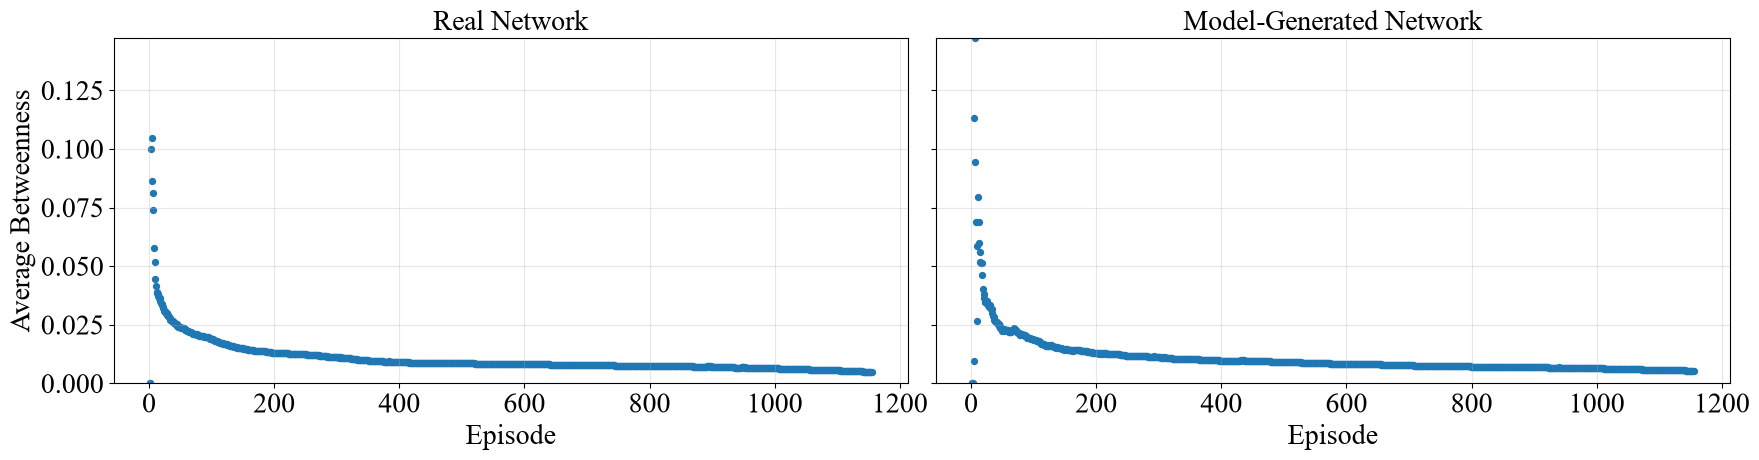

In [7]:
x = df['episodio']

# Font consistent with Springer/LNCS style
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20
})

# Calculate common Y-axis limits
y_min = min(
    np.min(avg_betweenness),
    np.min(avg_betweenness_syn_rl)
)

y_max = max(
    np.max(avg_betweenness),
    np.max(avg_betweenness_syn_rl)
)

fig, axs = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Real Network
axs[0].scatter(
    x,
    avg_betweenness,
    s=18
)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Betweenness")
axs[0].grid(alpha=0.3)

# Model + Real Data
axs[1].scatter(
    x,
    avg_betweenness_syn_rl,
    s=18
)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same Y-axis limits
for ax in axs:
    ax.set_ylim(y_min, y_max)

plt.tight_layout()

# Save as high-resolution image
#plt.savefig(
#    "average_betweenness_episode.png",
#    dpi=300,
#    bbox_inches="tight"
#)

#fig.suptitle("Evolution of Average Betweenness per Episode")
plt.tight_layout(w_pad=0.1)
plt.show()

## Closeness evolution

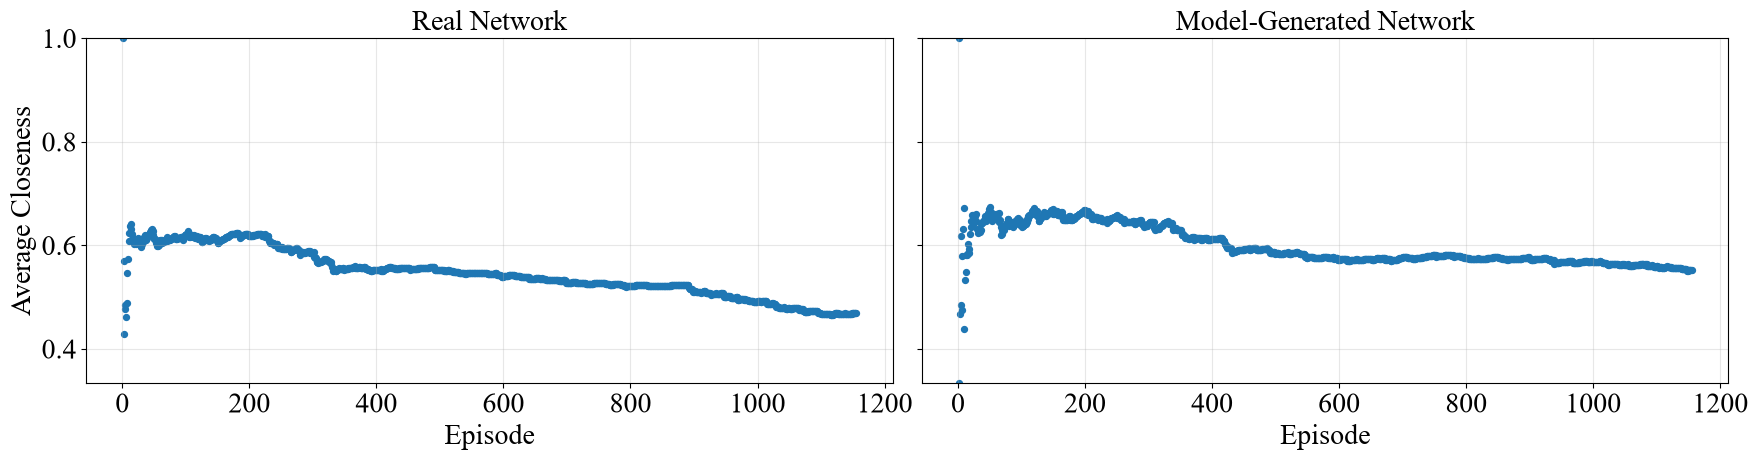

In [8]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_closeness),
    np.min(avg_closeness_syn_rl)
)

y_max = max(
    np.max(avg_closeness),
    np.max(avg_closeness_syn_rl)
)

fig, axs = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Real Network
axs[0].scatter(x, avg_closeness, s=18)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Closeness")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_closeness_syn_rl, s=18)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same Y-axis limits
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle("Evolution of Average Closeness per Episode")
plt.tight_layout(w_pad=0.1)
plt.show()

## Normalized average degree evolution

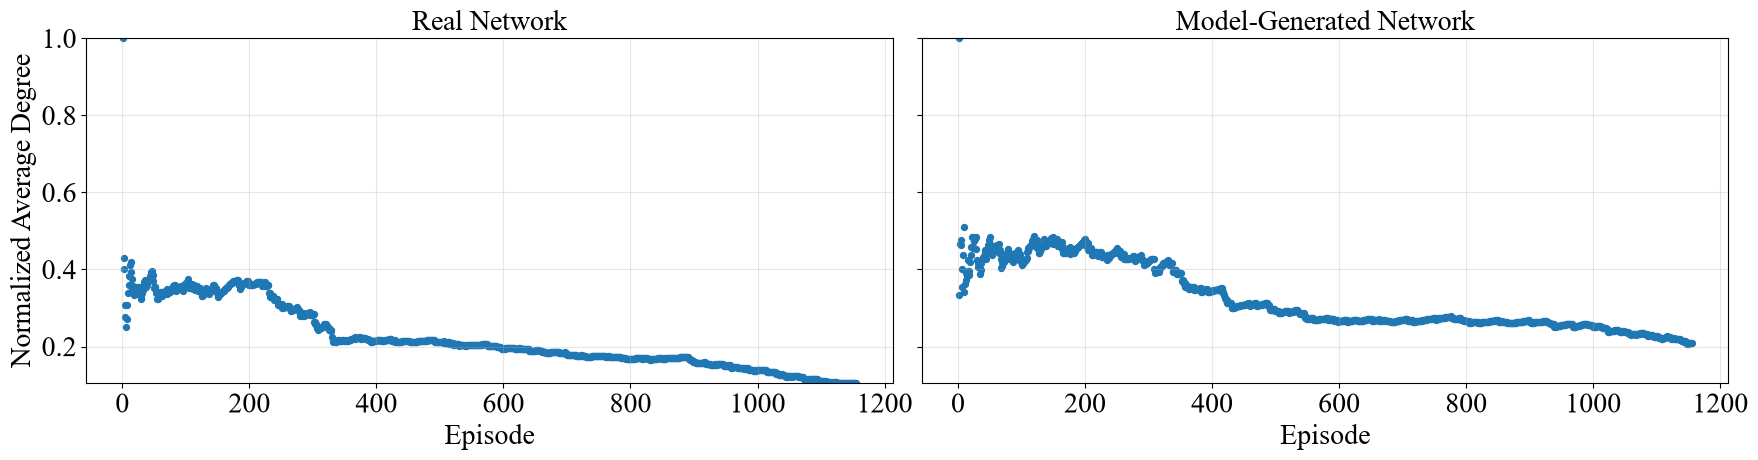

In [9]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_degree_normalized),
    np.min(avg_degree_normalized_syn_rl)
)

y_max = max(
    np.max(avg_degree_normalized),
    np.max(avg_degree_normalized_syn_rl)
)

fig, axs = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Real Network
axs[0].scatter(x, avg_degree_normalized, s=18)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Normalized Average Degree")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_degree_normalized_syn_rl, s=18)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same Y-axis limits
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle("Evolution of Normalized Average Degree per Episode")
plt.tight_layout(w_pad=0.1)
plt.show()

## Average degree evolution

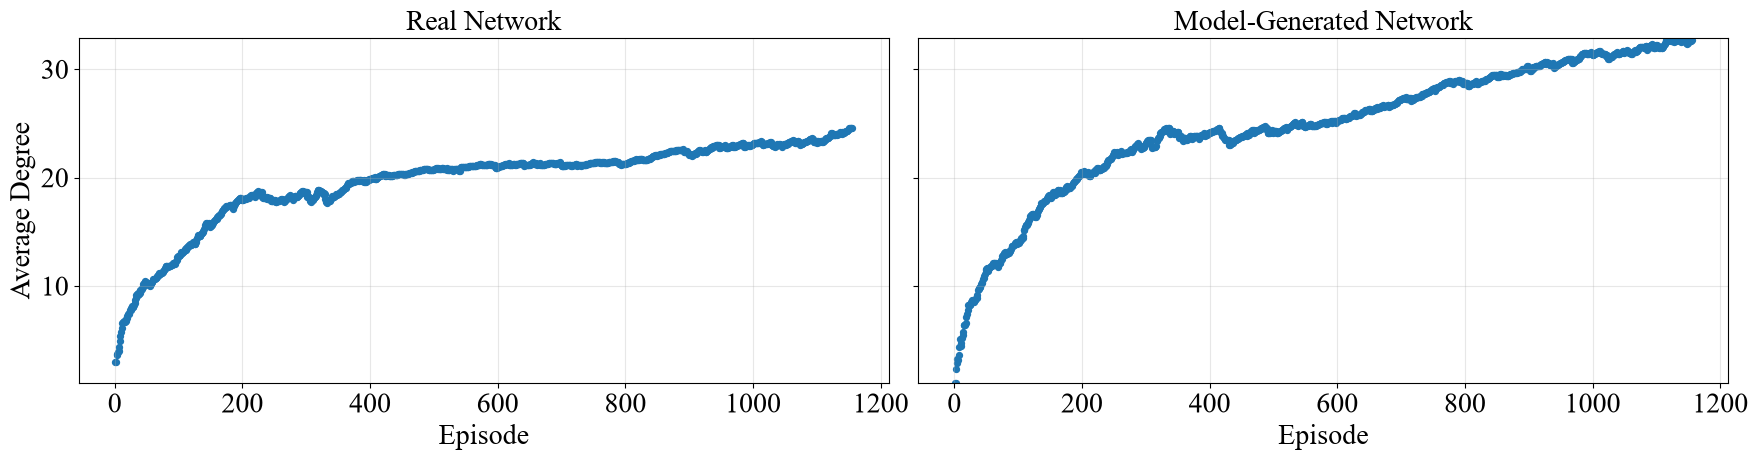

In [10]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_degree),
    np.min(avg_degree_syn_rl)
)

y_max = max(
    np.max(avg_degree),
    np.max(avg_degree_syn_rl)
)

fig, axs = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Real Network
axs[0].scatter(x, avg_degree, s=18)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Degree")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_degree_syn_rl, s=18)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same Y-axis limits
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle("Evolution of Average Degree per Episode")
plt.tight_layout(w_pad=0.1)
plt.show()

## Characteristic Path Length evolution

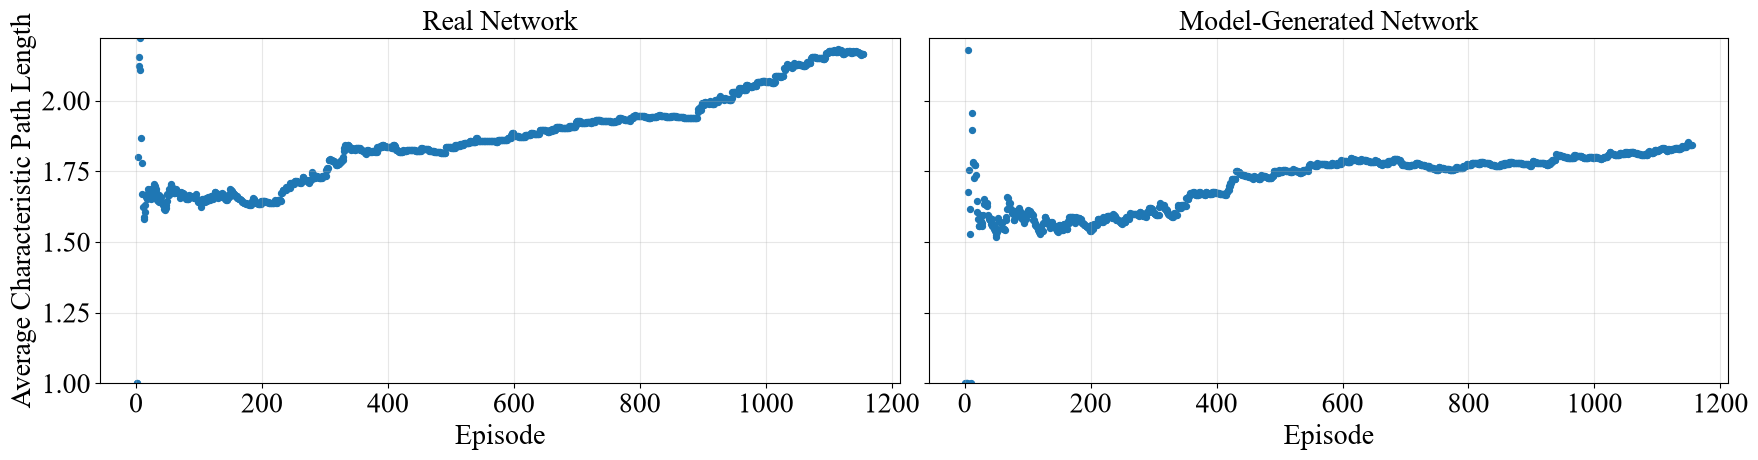

In [11]:
# Calculate common Y-axis limits
y_min = min(
    np.nanmin(np.array(avg_path_len, dtype=float)),
    np.min(avg_path_len_syn_rl)
)

y_max = max(
    np.nanmax(np.array(avg_path_len, dtype=float)),
    np.max(avg_path_len_syn_rl)
)

fig, axs = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Real Network
axs[0].scatter(x, avg_path_len, s=18)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Characteristic Path Length")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_path_len_syn_rl, s=18)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same Y-axis limits
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle("Evolution of Average Characteristic Path Length per Episode")
plt.tight_layout(w_pad=0.1)
plt.show()

# Viana metrics evolution: comparison between models

## Average Previous Team Experience per Episode

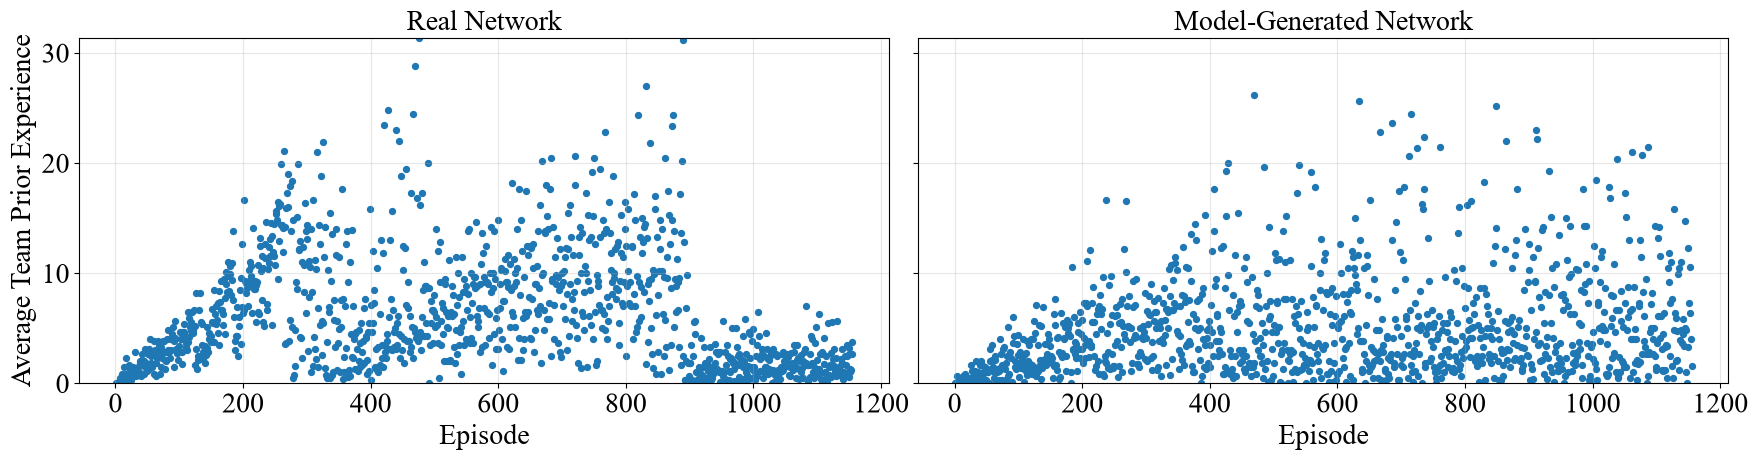

In [12]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_tm_exp_list),
    np.min(avg_previous_tm_exp_list_syn_rl)
)

y_max = max(
    np.max(avg_previous_tm_exp_list),
    np.max(avg_previous_tm_exp_list_syn_rl)
)

fig, axs = plt.subplots(
    1, 2,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# Real Network
axs[0].scatter(x, avg_previous_tm_exp_list, s=18)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Team Prior Experience")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_previous_tm_exp_list_syn_rl, s=18)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same Y-axis limits
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle("Evolution of Average Previous Team Experience per Episode")
plt.tight_layout(w_pad=0.1)
plt.show()

## Average Previous Team Collaborations per Episode

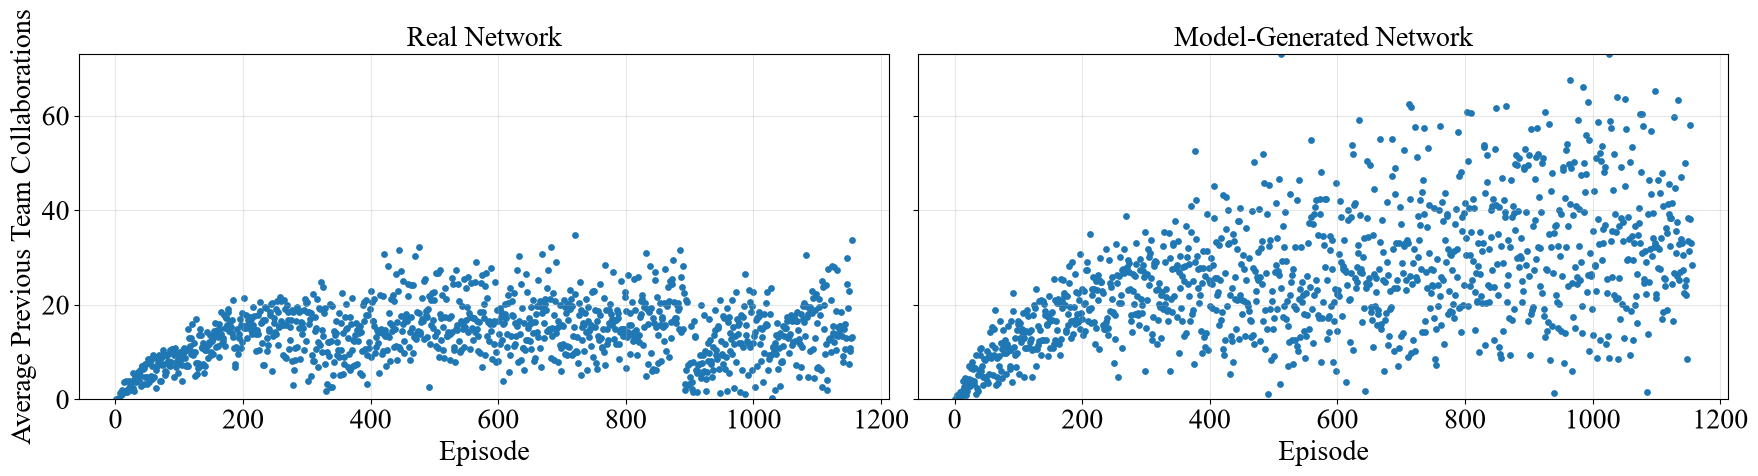

In [13]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_tm_shared_colabs_list),
    np.min(avg_previous_tm_shared_colabs_list_syn_rl)
)

y_max = max(
    np.max(avg_previous_tm_shared_colabs_list),
    np.max(avg_previous_tm_shared_colabs_list_syn_rl)
)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x, avg_previous_tm_shared_colabs_list, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Previous Team Collaborations")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_previous_tm_shared_colabs_list_syn_rl, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Evolution of Average Previous Team Collaborations per Episode",
#)
plt.tight_layout(w_pad=0.1)
plt.show()

## Average Team Clustering Coeff per Episode

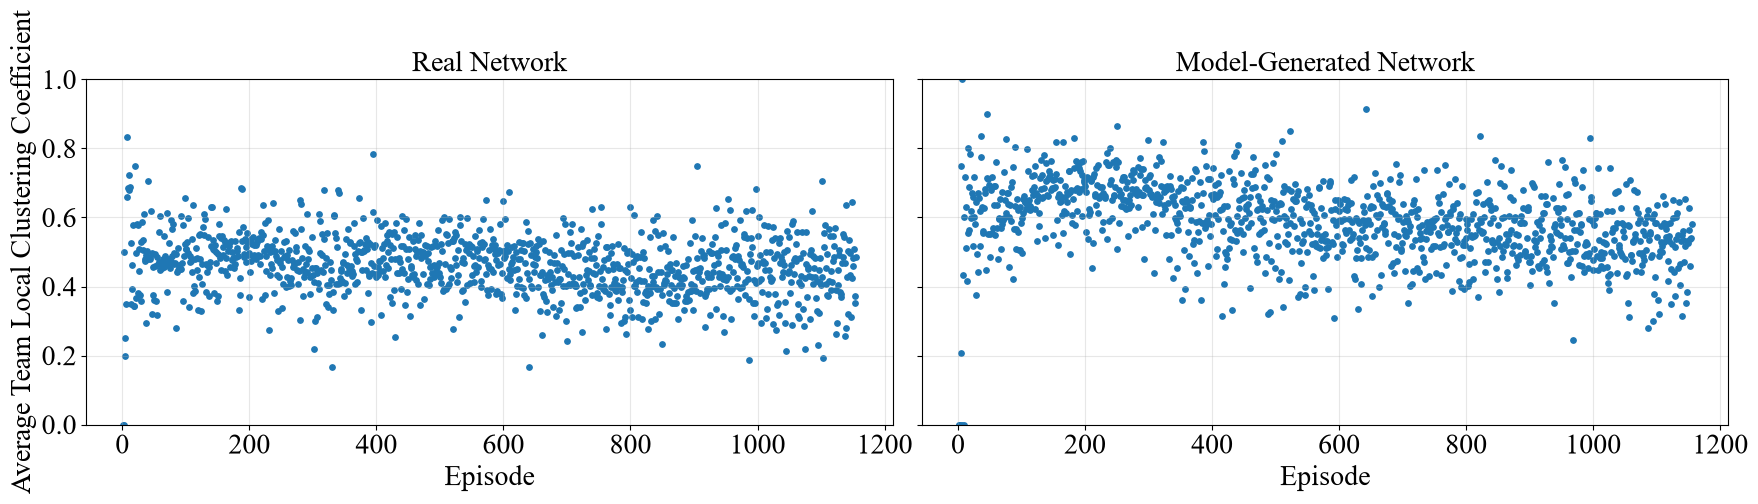

In [14]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_tm_clustering_coeff_list),
    np.min(avg_previous_tm_clustering_coeff_list_syn_rl)
)

y_max = max(
    np.max(avg_previous_tm_clustering_coeff_list),
    np.max(avg_previous_tm_clustering_coeff_list_syn_rl)
)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x, avg_previous_tm_clustering_coeff_list, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Team Local Clustering Coefficient")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_previous_tm_clustering_coeff_list_syn_rl, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Evolution of Average Team Local Clustering Coefficient per Episode",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Average Previous Team Closeness per Episode

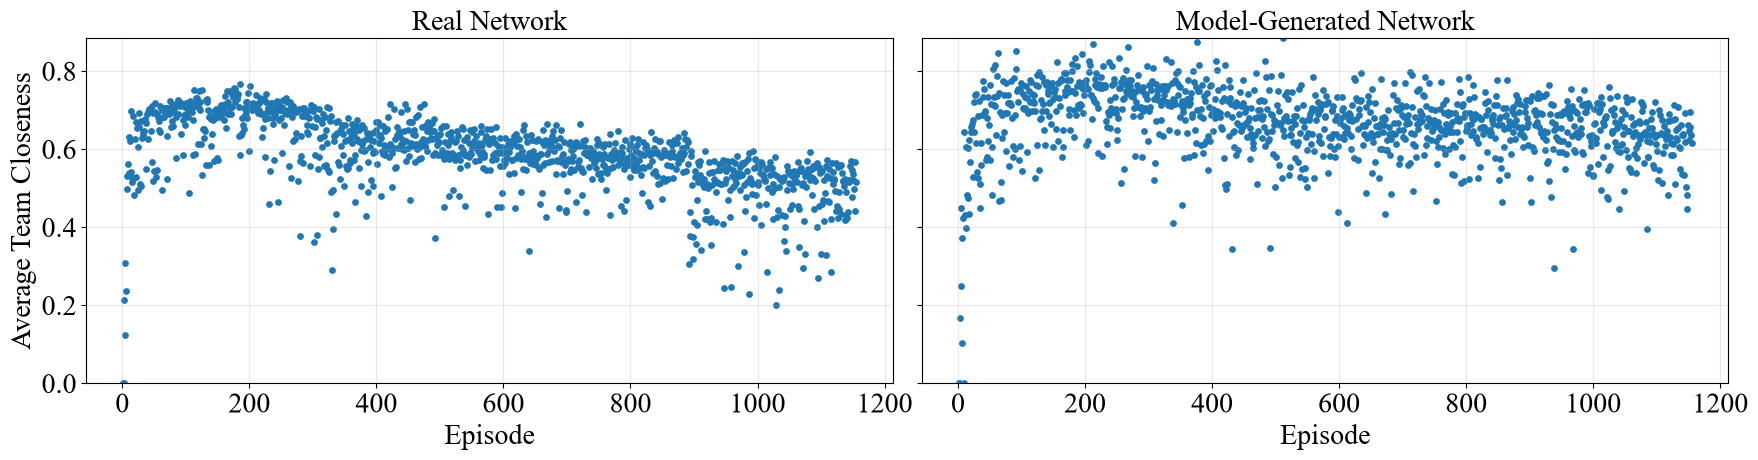

In [15]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_tm_closeness_list),
    np.min(avg_previous_tm_closeness_list_syn_rl)
)

y_max = max(
    np.max(avg_previous_tm_closeness_list),
    np.max(avg_previous_tm_closeness_list_syn_rl)
)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x, avg_previous_tm_closeness_list, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Team Closeness")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_previous_tm_closeness_list_syn_rl, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_ylim(y_min, y_max)

plt.tight_layout(w_pad=0.1)
plt.show()

## Average Previous Team Betweenness per Episode

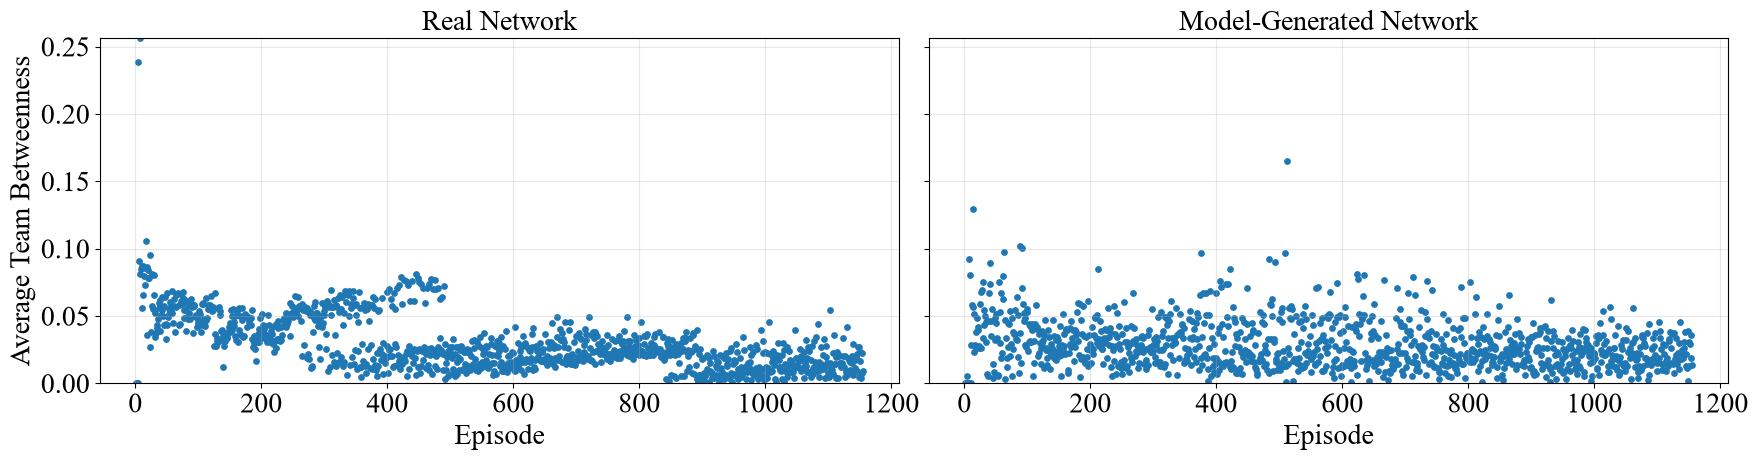

In [16]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_tm_betweenness_list),
    np.min(avg_previous_tm_betweenness_list_syn_rl)
)

y_max = max(
    np.max(avg_previous_tm_betweenness_list),
    np.max(avg_previous_tm_betweenness_list_syn_rl)
)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x, avg_previous_tm_betweenness_list, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Team Betweenness")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_previous_tm_betweenness_list_syn_rl, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Evolution of Average Team Betweenness per Episode",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Average Previous Team Individual Experience per Episode 

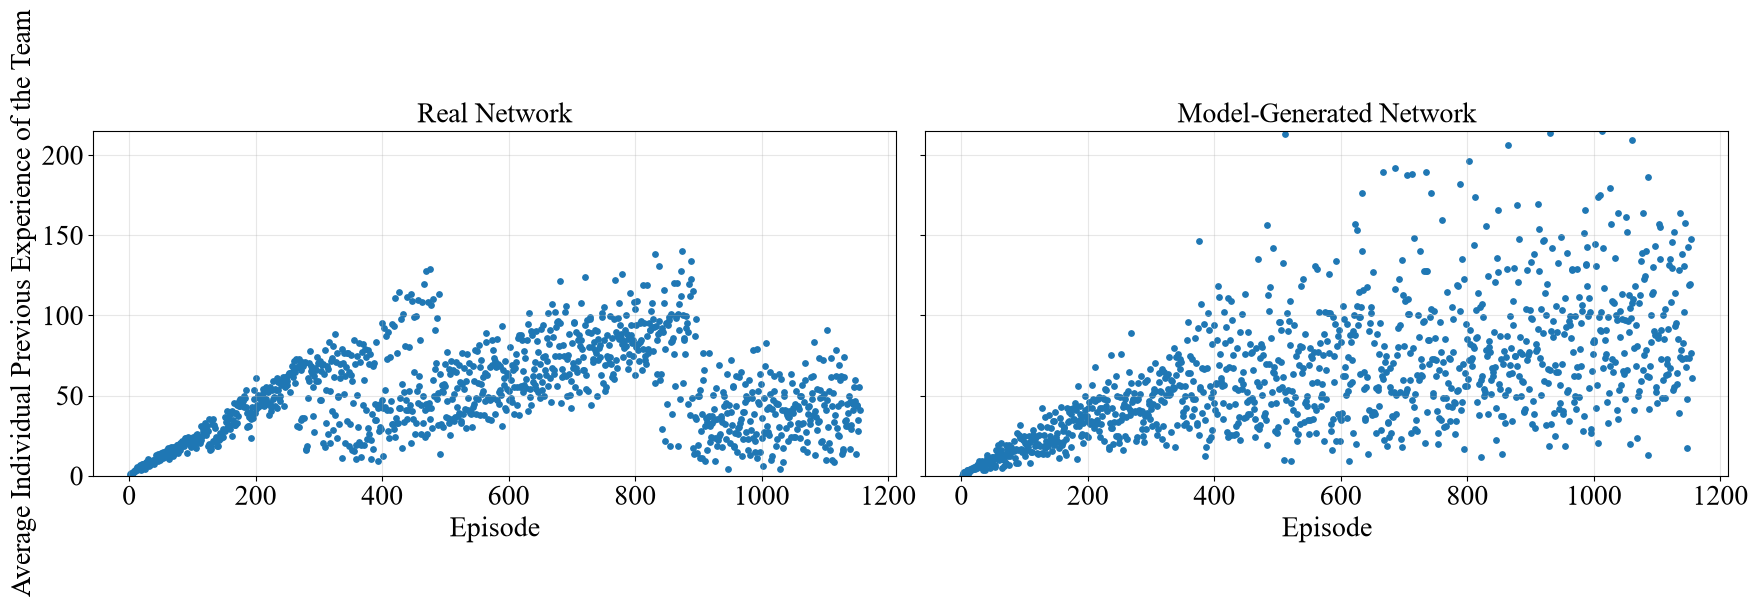

In [17]:
# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_individual_exp_list),
    np.min(avg_previous_individual_exp_list_syn_rl)
)

y_max = max(
    np.max(avg_previous_individual_exp_list),
    np.max(avg_previous_individual_exp_list_syn_rl)
)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x, avg_previous_individual_exp_list, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Individual Previous Experience of the Team")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x, avg_previous_individual_exp_list_syn_rl, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Evolution of Average Individual Previous Team Experience per Episode",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Average Previous Team Rating per Episode

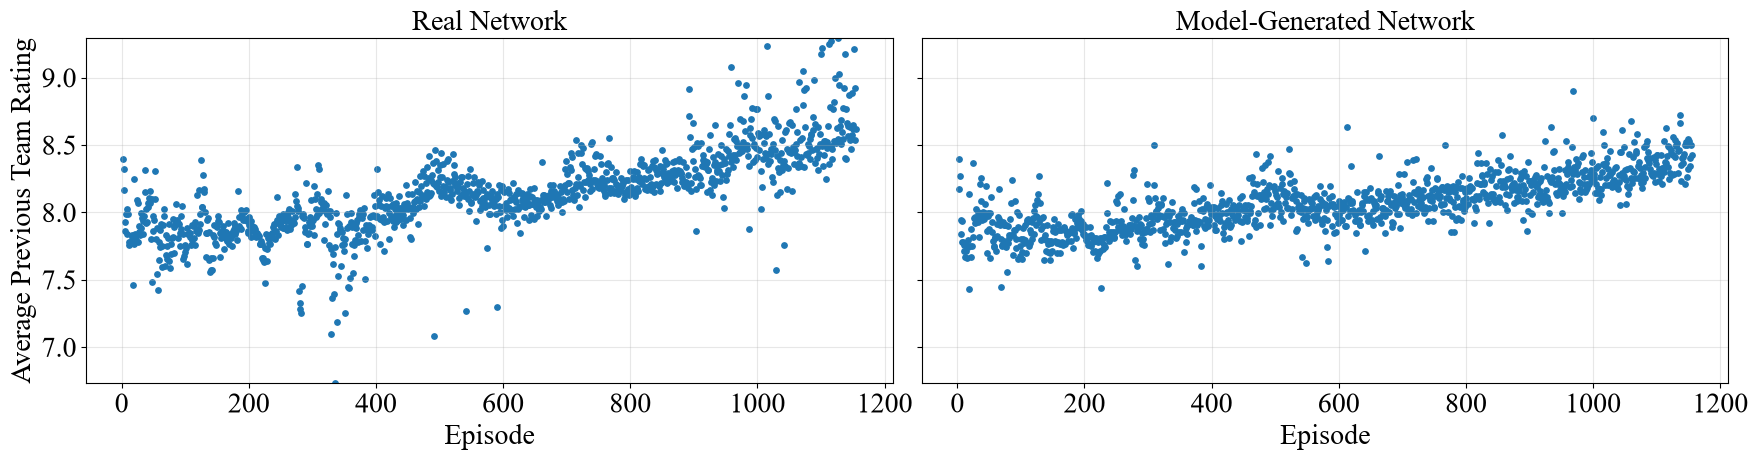

In [18]:
# Ignore the first episode
x1 = x[1:]

# Calculate common Y-axis limits
y_min = min(
    np.min(avg_previous_team_rating_list[1:]),
    np.min(avg_previous_team_rating_list_syn_rl[1:])
)

y_max = max(
    np.max(avg_previous_team_rating_list[1:]),
    np.max(avg_previous_team_rating_list_syn_rl[1:])
)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x1, avg_previous_team_rating_list[1:], s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Average Previous Team Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x1, avg_previous_team_rating_list_syn_rl[1:], s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Episode")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Evolution of Average Previous Team Rating per Episode",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

# Viana metrics against rating: comparison between models

## Relationship Between Average Previous Team Experience and Rating

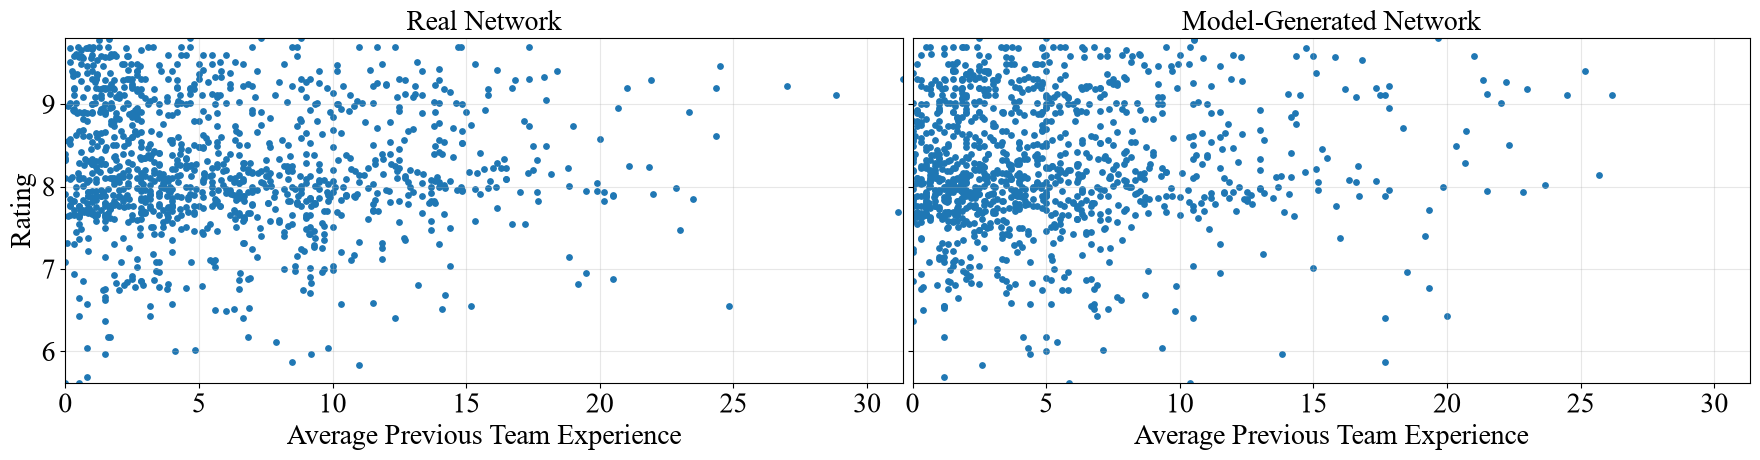

In [19]:
# Data
y_real = df["rating"].to_list()

# Common limits
x_min = min(
    np.min(avg_previous_tm_exp_list),
    np.min(avg_previous_tm_exp_list_syn_rl)
)

x_max = max(
    np.max(avg_previous_tm_exp_list),
    np.max(avg_previous_tm_exp_list_syn_rl)
)

y_min = min(y_real)
y_max = max(y_real)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(avg_previous_tm_exp_list, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Previous Team Experience")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(avg_previous_tm_exp_list_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Previous Team Experience")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Previous Team Experience and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Relationship Between Average Previous Team Collaborations and Rating

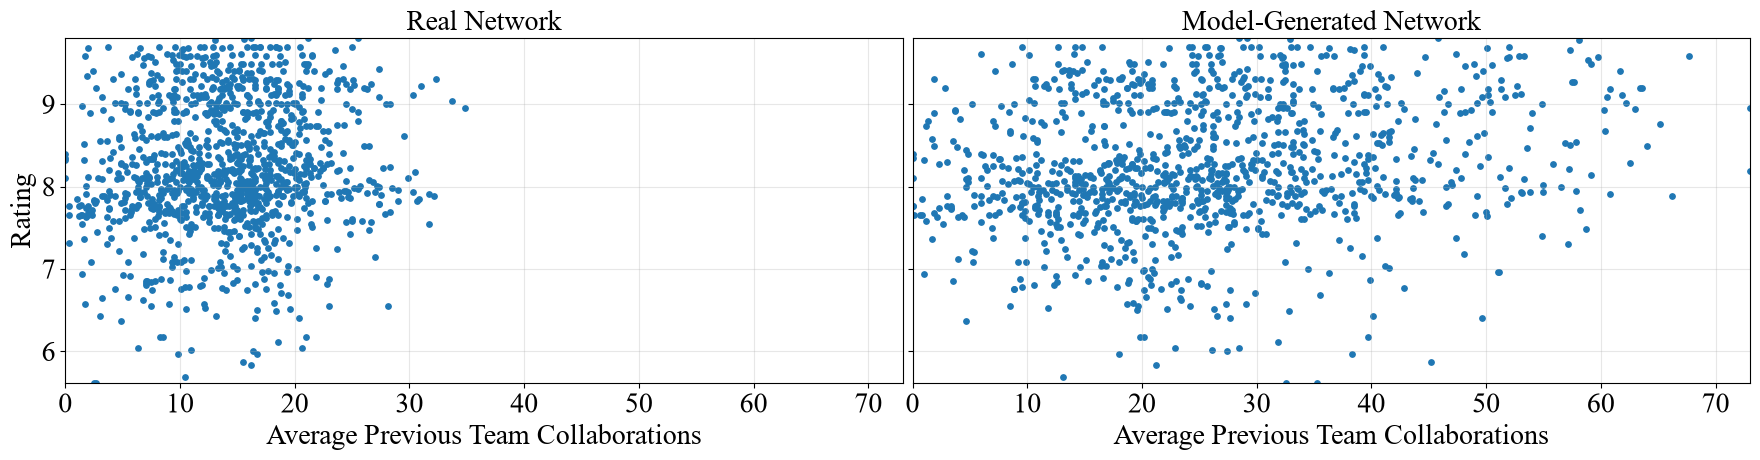

In [20]:
# Data
y_real = df["rating"].to_list()

# Common limits
x_min = min(
    np.min(avg_previous_tm_shared_colabs_list),
    np.min(avg_previous_tm_shared_colabs_list_syn_rl)
)

x_max = max(
    np.max(avg_previous_tm_shared_colabs_list),
    np.max(avg_previous_tm_shared_colabs_list_syn_rl)
)

y_min = min(y_real)
y_max = max(y_real)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(avg_previous_tm_shared_colabs_list, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Previous Team Collaborations")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(avg_previous_tm_shared_colabs_list_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Previous Team Collaborations")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Previous Team Collaborations and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Relationship Between Average Team Local Clustering Coefficient and Rating

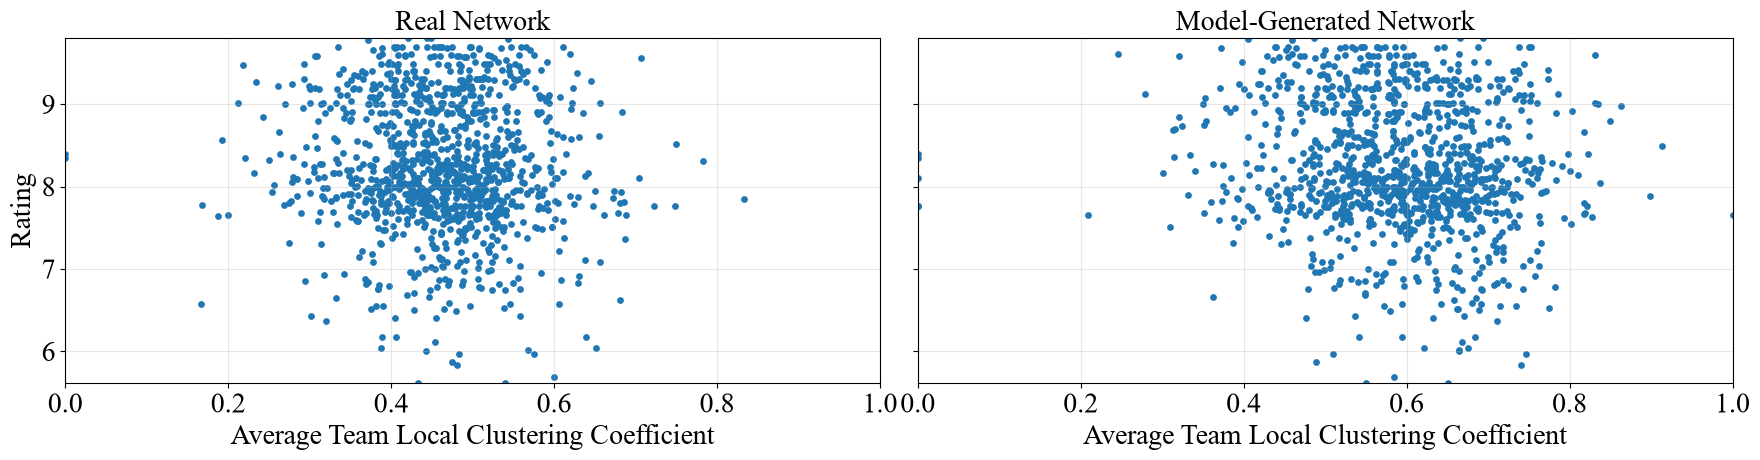

In [21]:
# Data
y_real = df["rating"].to_list()

# Common limits
x_min = min(
    np.min(avg_previous_tm_clustering_coeff_list),
    np.min(avg_previous_tm_clustering_coeff_list_syn_rl)
)

x_max = max(
    np.max(avg_previous_tm_clustering_coeff_list),
    np.max(avg_previous_tm_clustering_coeff_list_syn_rl)
)

y_min = min(y_real)
y_max = max(y_real)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(avg_previous_tm_clustering_coeff_list, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Team Local Clustering Coefficient")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(avg_previous_tm_clustering_coeff_list_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Team Local Clustering Coefficient")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Team Local Clustering Coefficient and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Relationship Between Average Team Closeness and Rating

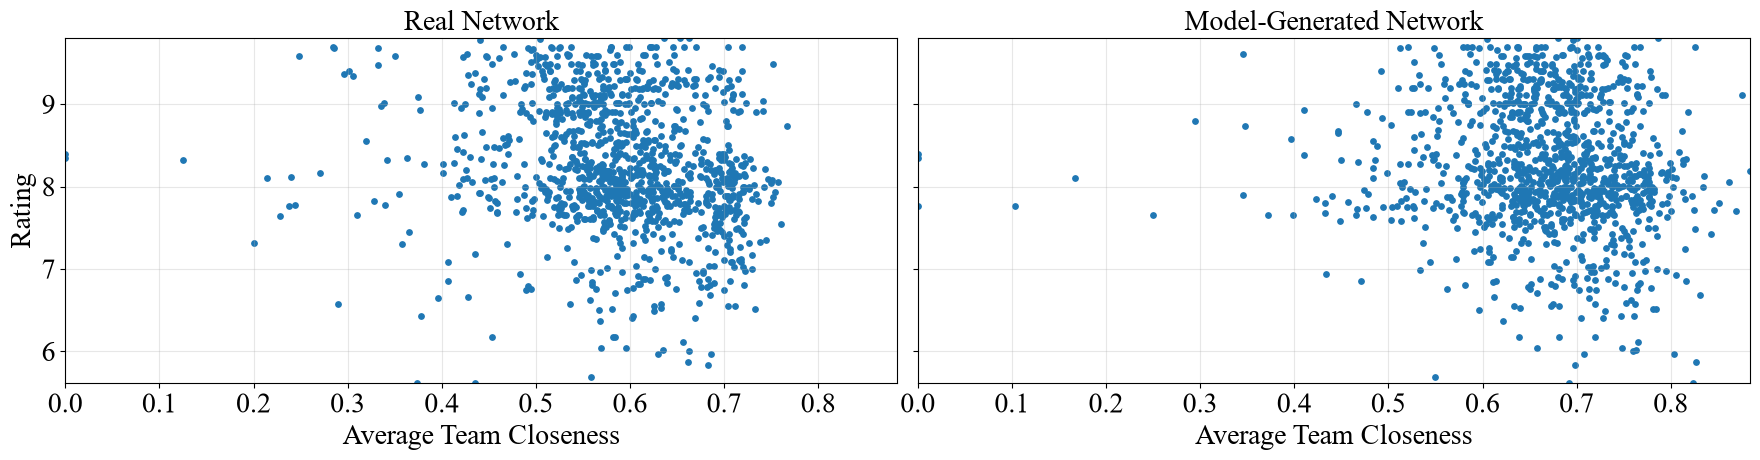

In [22]:
# Data
y_real = df["rating"].to_list()

# Common limits
x_min = min(
    np.min(avg_previous_tm_closeness_list),
    np.min(avg_previous_tm_closeness_list_syn_rl)
)

x_max = max(
    np.max(avg_previous_tm_closeness_list),
    np.max(avg_previous_tm_closeness_list_syn_rl)
)

y_min = min(y_real)
y_max = max(y_real)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(avg_previous_tm_closeness_list, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Team Closeness")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(avg_previous_tm_closeness_list_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Team Closeness")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Team Closeness and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Relationship Between Average Team Betweenness and Rating

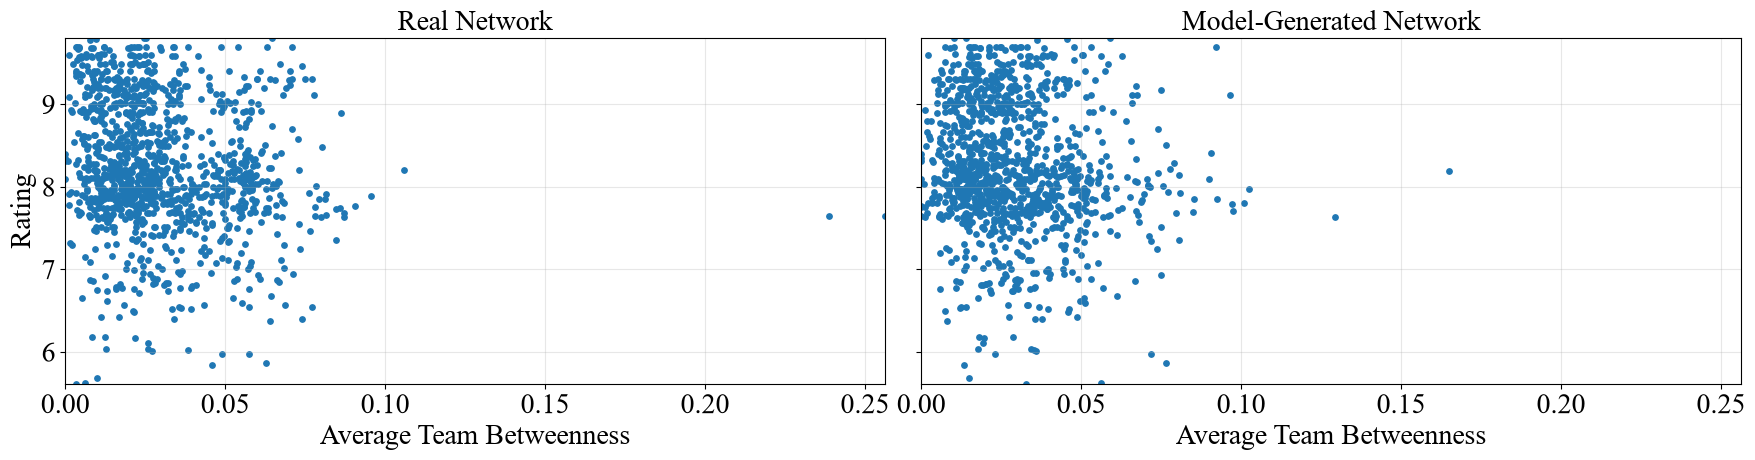

In [23]:
# Data
y_real = df["rating"].to_list()

# Common limits
x_min = min(
    np.min(avg_previous_tm_betweenness_list),
    np.min(avg_previous_tm_betweenness_list_syn_rl)
)

x_max = max(
    np.max(avg_previous_tm_betweenness_list),
    np.max(avg_previous_tm_betweenness_list_syn_rl)
)

y_min = min(y_real)
y_max = max(y_real)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(avg_previous_tm_betweenness_list, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Team Betweenness")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(avg_previous_tm_betweenness_list_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Team Betweenness")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Team Betweenness and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Relationship Between Average Individual Previous Team Experience and Rating

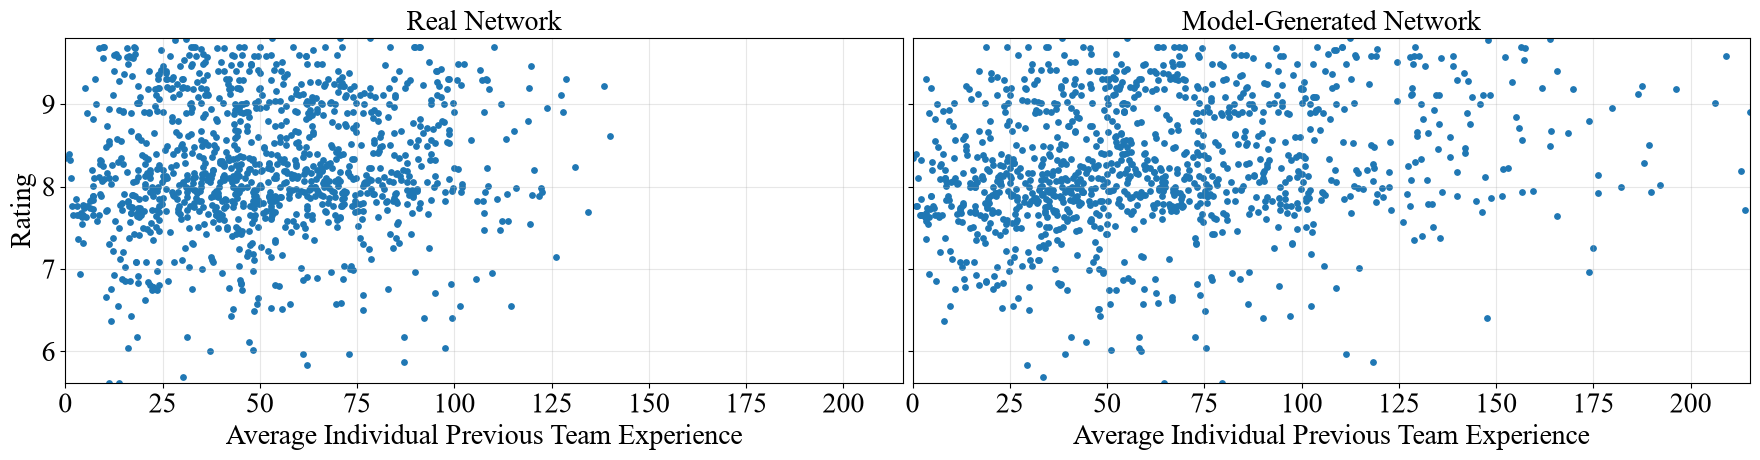

In [24]:
# Data
y_real = df["rating"].to_list()

# Common limits
x_min = min(
    np.min(avg_previous_individual_exp_list),
    np.min(avg_previous_individual_exp_list_syn_rl)
)

x_max = max(
    np.max(avg_previous_individual_exp_list),
    np.max(avg_previous_individual_exp_list_syn_rl)
)

y_min = min(y_real)
y_max = max(y_real)

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(avg_previous_individual_exp_list, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Individual Previous Team Experience")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(avg_previous_individual_exp_list_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Individual Previous Team Experience")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Individual Previous Team Experience and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()

## Relationship Between Average Previous Team Rating and Rating

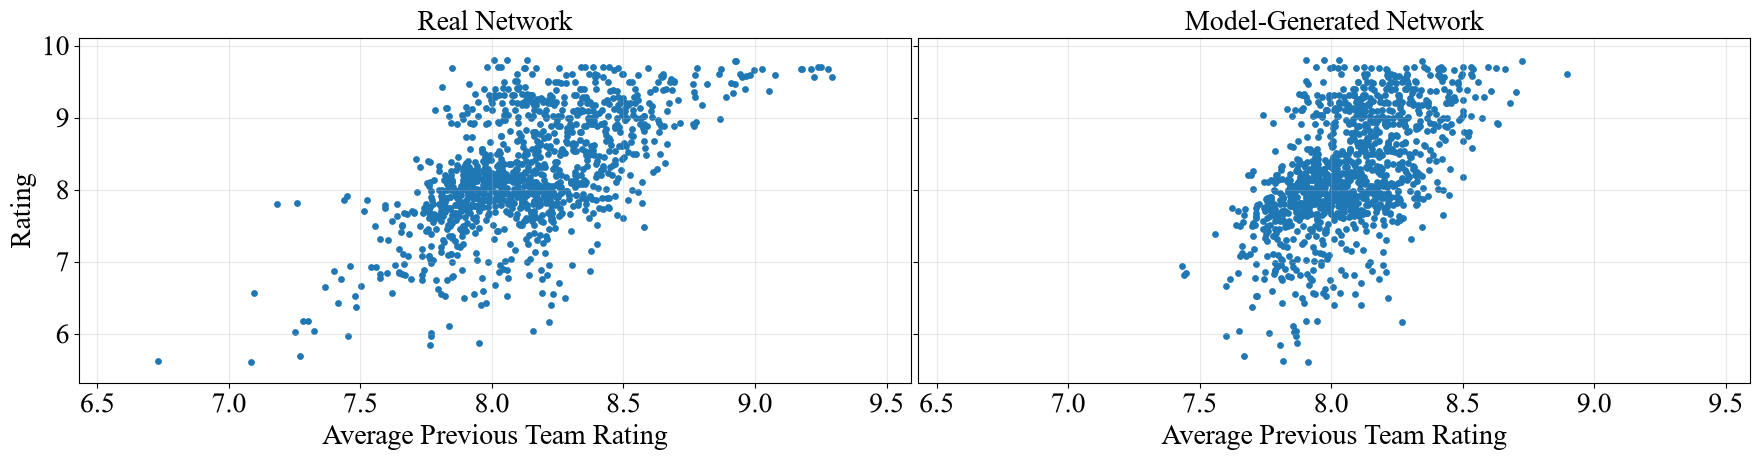

In [25]:
# Data (first episode omitted)
x_real = avg_previous_team_rating_list[1:]
x_syn_rl = avg_previous_team_rating_list_syn_rl[1:]

y = df["rating"].to_list()
y_real = y[1:]

# Common limits
x_min = min(x_real)-0.3
x_max = max(x_real)+0.3

y_min = min(y_real)-0.3
y_max = max(y_real)+0.3

fig, axs = plt.subplots(1, 2, figsize=(18, 5), sharex=True, sharey=True)

# Real network
axs[0].scatter(x_real, y_real, s=15)
axs[0].set_title("Real Network")
axs[0].set_xlabel("Average Previous Team Rating")
axs[0].set_ylabel("Rating")
axs[0].grid(alpha=0.3)

# Model-Generated Network
axs[1].scatter(x_syn_rl, y_real, s=15)
axs[1].set_title("Model-Generated Network")
axs[1].set_xlabel("Average Previous Team Rating")
axs[1].grid(alpha=0.3)

# Same limits for both plots
for ax in axs:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

#fig.suptitle(
#    "Relationship Between Average Previous Team Rating and Rating",
#)

plt.tight_layout(w_pad=0.1)
plt.show()